# drugMR: Interpreting Results

> *A guided walkthrough of a completed **drugMR** run outside the dashboard, dissecting the results tables directly, from the first genetic signal to the final evidence profile of each prioritised target.*

### Overview

Rather than browsing results in the dashboard, this notebook opens the raw results tables of a completed run and dissects them one stage at a time. Each section loads the relevant table, shows what its columns mean, and highlights what separates a convincing target from a weak one.

### Requirements

| | |
|:--|:--|
| **Repository** | The `drugMR` repository cloned locally. |
| **Environment** | Created with `env/bootstrap.sh`, which installs the `drugmr` package in editable mode. No separate `pip install` is needed. |
| **Kernel** | This notebook running on the environment's kernel (`.venv` in the repository root). |
| **Run** | A completed run under `runs/<run_id>/`. If the pipeline ran on a remote HPC, fetch it first with `notebooks/00_drugmr.ipynb`. |

In [1]:
from drugmr.interpret import ResultsExplorer

The outputs below come from the synthetic demo run (see *Try the demo* in the README), so they can be shown publicly. To explore your own run, set `run_id` to its folder name under `runs/` and `root` to `"../runs"`.

In [2]:
explorer = ResultsExplorer(
    run_id="DEMO_demo_pqtl_2026-10-08_13-22-06_934a4ea",
    root="../runs_demo",
)

## 1. Run overview

What the run is, the thresholds every later stage is judged against, and how many proteins survive each stage.

**`run_info()`** lists the run identity, the code and container that produced it, the outcome GWAS inputs and every gate.

In [3]:
explorer.run_info()

,value
setting,
Run ID,DEMO_demo_pqtl_2026-10-08_13-22-06_934a4ea
Outcome,DEMO
pQTL dataset,demo_pqtl
Status,success
Created,2026-10-08T13:23:15.004367
Git commit,934a4ea (uncommitted changes)
Container,drugmr (sha256:2dec5aebec2c)
Host,local machine
Cases,40000


**`funnel()`** counts the proteins remaining after each stage. The share column is taken against the stage named in the note.

In [4]:
explorer.funnel()

,n,share,note
stage,,,
Tested in cis-MR,16,,"15 Wald ratio, 1 multi-instrument"
Instruments (SNPs),17,,"median 1 per protein, min F 92.2"
Passed cis-MR,8,50%,"of tested, FDR and heterogeneity gates"
Colocalised (COLOC),5,62%,"of cis-MR hits, PP4 >= 0.7"
Colocalised (PWCoCo),6,75%,"of cis-MR hits, PP4 >= 0.7"
Prioritised,6,75%,"of cis-MR hits, COLOC or PWCoCo"
SMR support (bulk),3,50%,"of prioritised, bulk tissue eQTL"
SMR support (single cell),2,33%,"of prioritised, cell type eQTL"
SMR support (either),4,67%,of prioritised


## 2. Causal estimates (cis-MR)

The effect of each protein on the outcome. When a higher protein level raises risk, the drug direction is to inhibit; when it lowers risk, the drug direction is to activate.

**`cis_mr()`** gives one row per protein passing the cis-MR gate, with the odds ratio and 95% CI, P, FDR and drug direction.

In [5]:
explorer.cis_mr()

,protein,method,n_instruments,beta,se,OR,OR 95% CI,P,FDR q,Cochran's Q P,Egger intercept P,effect,drug direction
symbol,,,,,,,,,,,,,
SEPTIN14,SEPTIN14_ENSG00000154997,IVW,2,0.1971,0.0195,1.218,1.172 to 1.265,5.515791e-24,8.825266e-23,0.348787,NaN,higher protein raises risk,inhibit
EDARADD,EDARADD_ENSG00000186197,Wald ratio,1,0.2203,0.0221,1.246,1.194 to 1.302,2.355132e-23,1.884105e-22,NaN,NaN,higher protein raises risk,inhibit
SH3BGR,SH3BGR_ENSG00000185437,Wald ratio,1,0.2404,0.0253,1.272,1.210 to 1.336,1.765358e-21,9.415241e-21,NaN,NaN,higher protein raises risk,inhibit
CALHM4,CALHM4_ENSG00000164451,Wald ratio,1,0.2092,0.0222,1.233,1.180 to 1.287,3.641950e-21,1.456780e-20,NaN,NaN,higher protein raises risk,inhibit
STX1A,STX1A_ENSG00000106089,Wald ratio,1,0.2713,0.0318,1.312,1.232 to 1.396,1.304252e-17,4.173607e-17,NaN,NaN,higher protein raises risk,inhibit
BCLAF1,BCLAF1_ENSG00000029363,Wald ratio,1,-0.1796,0.0230,0.836,0.799 to 0.874,5.498200e-15,1.466187e-14,NaN,NaN,higher protein lowers risk,activate
SPRR2G,SPRR2G_ENSG00000159516,Wald ratio,1,0.0906,0.0154,1.095,1.062 to 1.128,3.602362e-09,8.233971e-09,NaN,NaN,higher protein raises risk,inhibit
ADH1C,ADH1C_ENSG00000248144,Wald ratio,1,-0.0766,0.0289,0.926,0.875 to 0.980,7.909600e-03,1.581920e-02,NaN,NaN,higher protein lowers risk,activate


With `hits_only=False` it returns every protein tested, with a column saying whether it passed.

In [6]:
explorer.cis_mr(hits_only=False)

,protein,method,n_instruments,beta,se,OR,OR 95% CI,P,FDR q,Cochran's Q P,Egger intercept P,effect,drug direction,passed cis-MR
symbol,,,,,,,,,,,,,,
SEPTIN14,SEPTIN14_ENSG00000154997,IVW,2,0.1971,0.0195,1.218,1.172 to 1.265,5.515791e-24,8.825266e-23,0.348787,NaN,higher protein raises risk,inhibit,True
EDARADD,EDARADD_ENSG00000186197,Wald ratio,1,0.2203,0.0221,1.246,1.194 to 1.302,2.355132e-23,1.884105e-22,NaN,NaN,higher protein raises risk,inhibit,True
SH3BGR,SH3BGR_ENSG00000185437,Wald ratio,1,0.2404,0.0253,1.272,1.210 to 1.336,1.765358e-21,9.415241e-21,NaN,NaN,higher protein raises risk,inhibit,True
CALHM4,CALHM4_ENSG00000164451,Wald ratio,1,0.2092,0.0222,1.233,1.180 to 1.287,3.641950e-21,1.456780e-20,NaN,NaN,higher protein raises risk,inhibit,True
STX1A,STX1A_ENSG00000106089,Wald ratio,1,0.2713,0.0318,1.312,1.232 to 1.396,1.304252e-17,4.173607e-17,NaN,NaN,higher protein raises risk,inhibit,True
BCLAF1,BCLAF1_ENSG00000029363,Wald ratio,1,-0.1796,0.0230,0.836,0.799 to 0.874,5.498200e-15,1.466187e-14,NaN,NaN,higher protein lowers risk,activate,True
SPRR2G,SPRR2G_ENSG00000159516,Wald ratio,1,0.0906,0.0154,1.095,1.062 to 1.128,3.602362e-09,8.233971e-09,NaN,NaN,higher protein raises risk,inhibit,True
ADH1C,ADH1C_ENSG00000248144,Wald ratio,1,-0.0766,0.0289,0.926,0.875 to 0.980,7.909600e-03,1.581920e-02,NaN,NaN,higher protein lowers risk,activate,True
MYH4,MYH4_ENSG00000264424,Wald ratio,1,-0.0278,0.0254,0.973,0.925 to 1.022,2.728791e-01,4.851184e-01,NaN,NaN,higher protein lowers risk,activate,False


**`instruments()`** shows the SNPs behind each estimate: alleles, pQTL and outcome effects, F statistic and the Steiger direction test.

In [7]:
explorer.instruments()

,protein,SNP,effect allele,other allele,EAF,pQTL beta,pQTL P,F,outcome beta,outcome P,Wald ratio,Steiger correct direction,Steiger P,palindromic
symbol,,,,,,,,,,,,,,
ADH1C,ADH1C_ENSG00000248144,rs35146617,T,C,0.2781,0.3531,1.077434e-26,114.4,-0.0271,7.909600e-03,-0.0766,True,5.252191e-24,False
BCLAF1,BCLAF1_ENSG00000029363,rs9389374,A,G,0.3517,0.4160,2.078736e-43,190.8,-0.0747,5.498200e-15,-0.1796,True,5.150572e-35,False
CALHM4,CALHM4_ENSG00000164451,rs67209301,G,A,0.2117,0.5042,2.014641e-51,227.6,0.1055,3.641950e-21,0.2092,True,2.028850e-40,False
EDARADD,EDARADD_ENSG00000186197,rs601065,A,G,0.3160,0.4437,5.317849e-48,211.9,0.0978,2.355132e-23,0.2203,True,3.569430e-37,False
SEPTIN14,SEPTIN14_ENSG00000154997,rs12532566,A,G,0.1575,0.4859,1.449300e-37,164.1,0.1034,1.511397e-16,0.2129,True,9.378941e-30,False
SEPTIN14,SEPTIN14_ENSG00000154997,rs7777501,A,G,0.4397,0.3081,2.810803e-24,103.3,0.0542,3.775955e-09,0.1759,True,6.641248e-20,False
SH3BGR,SH3BGR_ENSG00000185437,rs2037924,A,G,0.1912,0.4595,6.990551e-38,165.5,0.1105,1.765358e-21,0.2404,True,3.941279e-29,False
SPRR2G,SPRR2G_ENSG00000159516,rs499893,T,C,0.4468,0.5978,1.460548e-121,549.7,0.0542,3.602362e-09,0.0906,True,1.147404e-101,False
STX1A,STX1A_ENSG00000106089,rs4304220,A,G,0.2740,0.3223,7.677962e-22,92.2,0.0874,1.304252e-17,0.2713,True,2.169181e-16,False


**`sensitivity()`** compares IVW, MR Egger and weighted median for proteins with two or more instruments. Single instrument proteins use a Wald ratio, which has no sensitivity methods.

In [8]:
explorer.sensitivity()

7 single instrument proteins (Wald ratio) have no sensitivity methods and are not shown.


,protein,n_instruments,IVW beta,IVW P,Egger beta,Egger P,Weighted median beta,Weighted median P,Egger intercept P,Cochran's Q P,method signs
symbol,,,,,,,,,,,
SEPTIN14,SEPTIN14_ENSG00000154997,2,0.1971,5.515791e-24,NaN,NaN,NaN,NaN,NaN,0.348787,IVW only


**`forest_plot()`** plots the odds ratio and 95% CI of every prioritised target.

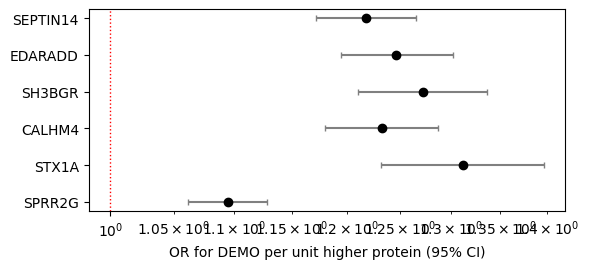

In [9]:
explorer.forest_plot();

## 3. Shared causal variant

A causal estimate is only convincing when the protein and the outcome share the same causal variant. COLOC assumes one signal per trait; PWCoCo conditions on each independent signal, so it can recover windows holding more than one.

**`colocalisation()`** gives COLOC and PWCoCo for each prioritised target, the best PWCoCo pair and which method supports it.

In [10]:
explorer.colocalisation()

,protein,COLOC PP4,COLOC PP3,COLOC top SNP,COLOC n SNPs,PWCoCo unconditioned PP4,PWCoCo best PP4,PWCoCo best PP3,PWCoCo best row,PWCoCo best pair (pQTL / outcome SNP),PWCoCo conditioned pairs,supported by
symbol,,,,,,,,,,,,
SH3BGR,SH3BGR_ENSG00000185437,1.000,0.000,rs2037924,1200,1.000,1.000,0.000,unconditioned,unconditioned / unconditioned,0,COLOC and PWCoCo
SEPTIN14,SEPTIN14_ENSG00000154997,0.996,0.004,rs12532566,1200,0.996,0.996,0.004,unconditioned,unconditioned / unconditioned,0,COLOC and PWCoCo
EDARADD,EDARADD_ENSG00000186197,0.995,0.005,rs601065,1200,0.995,0.995,0.005,unconditioned,unconditioned / unconditioned,0,COLOC and PWCoCo
CALHM4,CALHM4_ENSG00000164451,0.992,0.008,rs67209301,1200,0.992,0.992,0.008,unconditioned,unconditioned / unconditioned,0,COLOC and PWCoCo
STX1A,STX1A_ENSG00000106089,0.976,0.024,rs4304220,1200,0.976,0.976,0.024,unconditioned,unconditioned / unconditioned,0,COLOC and PWCoCo
SPRR2G,SPRR2G_ENSG00000159516,0.000,1.000,rs499893,1200,0.000,0.972,0.028,conditioned (pQTL only),rs310126 / unconditioned,5,PWCoCo only


With `hits_only=False` it covers every cis-MR hit, including those that did not colocalise.

In [11]:
explorer.colocalisation(hits_only=False)

,protein,COLOC PP4,COLOC PP3,COLOC top SNP,COLOC n SNPs,PWCoCo unconditioned PP4,PWCoCo best PP4,PWCoCo best PP3,PWCoCo best row,PWCoCo best pair (pQTL / outcome SNP),PWCoCo conditioned pairs,supported by
symbol,,,,,,,,,,,,
SH3BGR,SH3BGR_ENSG00000185437,1.000,0.000,rs2037924,1200,1.000,1.000,0.000,unconditioned,unconditioned / unconditioned,0,COLOC and PWCoCo
SEPTIN14,SEPTIN14_ENSG00000154997,0.996,0.004,rs12532566,1200,0.996,0.996,0.004,unconditioned,unconditioned / unconditioned,0,COLOC and PWCoCo
EDARADD,EDARADD_ENSG00000186197,0.995,0.005,rs601065,1200,0.995,0.995,0.005,unconditioned,unconditioned / unconditioned,0,COLOC and PWCoCo
CALHM4,CALHM4_ENSG00000164451,0.992,0.008,rs67209301,1200,0.992,0.992,0.008,unconditioned,unconditioned / unconditioned,0,COLOC and PWCoCo
STX1A,STX1A_ENSG00000106089,0.976,0.024,rs4304220,1200,0.976,0.976,0.024,unconditioned,unconditioned / unconditioned,0,COLOC and PWCoCo
SPRR2G,SPRR2G_ENSG00000159516,0.000,1.000,rs499893,1200,0.000,0.972,0.028,conditioned (pQTL only),rs310126 / unconditioned,5,PWCoCo only
ADH1C,ADH1C_ENSG00000248144,0.147,0.028,rs35146617,500,0.103,0.103,0.021,unconditioned,unconditioned / unconditioned,1,not colocalised
BCLAF1,BCLAF1_ENSG00000029363,0.000,1.000,rs9389374,1200,0.000,0.059,0.005,conditioned (outcome only),unconditioned / rs1564441*,3,not colocalised


**`coloc_priors()`** repeats COLOC under stricter priors. A target whose PP4 stays above the threshold under all of them is robust to the choice of prior.

In [12]:
explorer.coloc_priors()

,protein,PP4 most conservative,PP4 conservative,PP4 moderately conservative,passes under all priors
symbol,,,,,
ADH1C,ADH1C_ENSG00000248144,0.017,0.033,0.080,False
BCLAF1,BCLAF1_ENSG00000029363,0.000,0.000,0.000,False
CALHM4,CALHM4_ENSG00000164451,0.929,0.963,0.985,True
EDARADD,EDARADD_ENSG00000186197,0.952,0.976,0.990,True
SEPTIN14,SEPTIN14_ENSG00000154997,0.959,0.979,0.991,True
SH3BGR,SH3BGR_ENSG00000185437,1.000,1.000,1.000,True
SPRR2G,SPRR2G_ENSG00000159516,0.000,0.000,0.000,False
STX1A,STX1A_ENSG00000106089,0.802,0.890,0.953,True


**`lead_variants()`** shows the top cis variant of each protein with its outcome and pQTL effects on the same allele, and whether the direction they imply matches cis-MR.

In [13]:
explorer.lead_variants()

,protein,SNP,effect allele,other allele,EAF,GWAS beta,GWAS P,pQTL beta,pQTL P,implied direction vs cis-MR
symbol,,,,,,,,,,
ADH1C,ADH1C_ENSG00000248144,rs35146617,C,T,0.7219,0.0271,7.909600e-03,-0.3531,1.077434e-26,agrees
BCLAF1,BCLAF1_ENSG00000029363,rs9389374,G,A,0.6483,0.0747,5.498200e-15,-0.4160,2.078736e-43,agrees
CALHM4,CALHM4_ENSG00000164451,rs67209301,G,A,0.2117,0.1055,3.641950e-21,0.5042,2.014641e-51,agrees
EDARADD,EDARADD_ENSG00000186197,rs601065,A,G,0.3160,0.0978,2.355132e-23,0.4437,5.317849e-48,agrees
SEPTIN14,SEPTIN14_ENSG00000154997,rs12532566,A,G,0.1575,0.1034,1.511397e-16,0.4859,1.449300e-37,agrees
SH3BGR,SH3BGR_ENSG00000185437,rs2037924,A,G,0.1912,0.1105,1.765358e-21,0.4595,6.990551e-38,agrees
SPRR2G,SPRR2G_ENSG00000159516,rs499893,T,C,0.4468,0.0542,3.602362e-09,0.5978,1.460548e-121,agrees
STX1A,STX1A_ENSG00000106089,rs4304220,A,G,0.2740,0.0874,1.304252e-17,0.3223,7.677962e-22,agrees


## 4. xQTL triangulation

Whether QTL for other molecular traits of the same gene (xQTL) point to the same signal and direction as the pQTL. Bulk tissue and single cell xQTL are reported separately, and each check states whether its direction agrees with cis-MR.

**`smr()`** lists significant SMR results with a passing HEIDI test, one row per protein and tissue or cell type.

In [14]:
explorer.smr()

,protein,data type,QTL dataset,tissue / cell type,top SNP,b_SMR,se_SMR,P_SMR,q_SMR,P_HEIDI,HEIDI SNPs,cis-MR beta,direction vs cis-MR
symbol,,,,,,,,,,,,,
CALHM4,CALHM4_ENSG00000164451,bulk,demo_bulk,demo,rs4946190,0.2263,0.0311,3.506397e-13,1.753198e-12,0.049065,18,0.2092,agrees
CALHM4,CALHM4_ENSG00000164451,single cell,demo_sc,Ast,rs12527138,0.2131,0.0327,6.997740e-11,1.049661e-10,0.085360,14,0.2092,agrees
CALHM4,CALHM4_ENSG00000164451,single cell,demo_sc,Ext,rs4946190,0.2794,0.0520,7.767044e-08,7.767044e-08,0.167465,9,0.2092,agrees
SEPTIN14,SEPTIN14_ENSG00000154997,bulk,demo_bulk,demo,rs11238369,0.1985,0.0293,1.226079e-11,3.065198e-11,0.106952,20,0.1971,agrees
SH3BGR,SH3BGR_ENSG00000185437,single cell,demo_sc,Ast,rs2037924,0.2026,0.0291,3.195716e-12,9.587148e-12,0.079464,18,0.2404,agrees
STX1A,STX1A_ENSG00000106089,bulk,demo_bulk,demo,rs112524881,0.3590,0.0775,3.614091e-06,4.517614e-06,0.059222,10,0.2713,agrees


The `data_type` argument restricts it to bulk tissue or to single cell xQTL.

In [15]:
explorer.smr(data_type="bulk")

,protein,data type,QTL dataset,tissue / cell type,top SNP,b_SMR,se_SMR,P_SMR,q_SMR,P_HEIDI,HEIDI SNPs,cis-MR beta,direction vs cis-MR
symbol,,,,,,,,,,,,,
CALHM4,CALHM4_ENSG00000164451,bulk,demo_bulk,demo,rs4946190,0.2263,0.0311,3.506397e-13,1.753198e-12,0.049065,18,0.2092,agrees
SEPTIN14,SEPTIN14_ENSG00000154997,bulk,demo_bulk,demo,rs11238369,0.1985,0.0293,1.226079e-11,3.065198e-11,0.106952,20,0.1971,agrees
STX1A,STX1A_ENSG00000106089,bulk,demo_bulk,demo,rs112524881,0.3590,0.0775,3.614091e-06,4.517614e-06,0.059222,10,0.2713,agrees


In [16]:
explorer.smr(data_type="single_cell")

,protein,data type,QTL dataset,tissue / cell type,top SNP,b_SMR,se_SMR,P_SMR,q_SMR,P_HEIDI,HEIDI SNPs,cis-MR beta,direction vs cis-MR
symbol,,,,,,,,,,,,,
CALHM4,CALHM4_ENSG00000164451,single cell,demo_sc,Ast,rs12527138,0.2131,0.0327,6.997740e-11,1.049661e-10,0.085360,14,0.2092,agrees
CALHM4,CALHM4_ENSG00000164451,single cell,demo_sc,Ext,rs4946190,0.2794,0.0520,7.767044e-08,7.767044e-08,0.167465,9,0.2092,agrees
SH3BGR,SH3BGR_ENSG00000185437,single cell,demo_sc,Ast,rs2037924,0.2026,0.0291,3.195716e-12,9.587148e-12,0.079464,18,0.2404,agrees


**`hyprcoloc()`** lists clusters in which the pQTL, the outcome GWAS and an xQTL share one causal variant (posterior of at least 0.7).

In [17]:
explorer.hyprcoloc()

,protein,data type,QTL dataset,tissue / cell type,cluster,traits in cluster,posterior,regional probability,candidate SNP,posterior explained by SNP,effect allele,GWAS beta,pQTL beta,xQTL beta,xQTL vs pQTL direction
symbol,,,,,,,,,,,,,,,
CALHM4,CALHM4_ENSG00000164451,single cell,demo_sc,Ast,1,pQTL + GWAS + eQTL,0.936,1.0,rs67209301,0.205,G,0.1055,0.5042,0.4841,agrees
CALHM4,CALHM4_ENSG00000164451,single cell,demo_sc,Ext,1,pQTL + GWAS + eQTL,0.920,1.0,rs7357061,0.134,T,0.1039,0.5025,0.3719,agrees
CALHM4,CALHM4_ENSG00000164451,bulk,demo_bulk,demo,1,pQTL + GWAS + eQTL,0.915,1.0,rs7357061,0.203,T,0.1039,0.5025,0.4592,agrees
SEPTIN14,SEPTIN14_ENSG00000154997,bulk,demo_bulk,demo,1,pQTL + GWAS + eQTL,0.960,1.0,rs12666940,0.248,T,0.1034,0.4859,0.5154,agrees
SH3BGR,SH3BGR_ENSG00000185437,single cell,demo_sc,Ast,1,pQTL + GWAS + eQTL,1.000,1.0,rs2037924,1.000,A,0.1105,0.4595,0.5453,agrees
STX1A,STX1A_ENSG00000106089,bulk,demo_bulk,demo,1,pQTL + GWAS + eQTL,0.792,1.0,rs6968360,0.078,T,0.0879,0.3228,0.2179,agrees


With `supported_only=False` it returns every cluster, including those missing a trait or below the posterior threshold.

In [18]:
explorer.hyprcoloc(supported_only=False)

,protein,data type,QTL dataset,tissue / cell type,cluster,traits in cluster,posterior,regional probability,candidate SNP,posterior explained by SNP,effect allele,GWAS beta,pQTL beta,xQTL beta,xQTL vs pQTL direction,supported
symbol,,,,,,,,,,,,,,,,
CALHM4,CALHM4_ENSG00000164451,single cell,demo_sc,Ast,1,pQTL + GWAS + eQTL,0.936,1.0,rs67209301,0.205,G,0.1055,0.5042,0.4841,agrees,True
CALHM4,CALHM4_ENSG00000164451,single cell,demo_sc,Ext,1,pQTL + GWAS + eQTL,0.920,1.0,rs7357061,0.134,T,0.1039,0.5025,0.3719,agrees,True
CALHM4,CALHM4_ENSG00000164451,bulk,demo_bulk,demo,1,pQTL + GWAS + eQTL,0.915,1.0,rs7357061,0.203,T,0.1039,0.5025,0.4592,agrees,True
SEPTIN14,SEPTIN14_ENSG00000154997,bulk,demo_bulk,demo,1,pQTL + GWAS + eQTL,0.960,1.0,rs12666940,0.248,T,0.1034,0.4859,0.5154,agrees,True
SH3BGR,SH3BGR_ENSG00000185437,single cell,demo_sc,Ast,1,pQTL + GWAS + eQTL,1.000,1.0,rs2037924,1.000,A,0.1105,0.4595,0.5453,agrees,True
STX1A,STX1A_ENSG00000106089,bulk,demo_bulk,demo,1,pQTL + GWAS + eQTL,0.792,1.0,rs6968360,0.078,T,0.0879,0.3228,0.2179,agrees,True


**`pwcoco_qtl()`** gives PWCoCo of each xQTL against the pQTL and against the outcome GWAS.

In [19]:
explorer.pwcoco_qtl()

,protein,comparison,QTL dataset,tissue / cell type,unconditioned PP4,best PP4,best PP3,best pair,colocalised
symbol,,,,,,,,,
CALHM4,CALHM4_ENSG00000164451,eQTL vs GWAS,demo_sc,Ast,0.988,0.988,0.012,unconditioned / unconditioned,True
CALHM4,CALHM4_ENSG00000164451,eQTL vs GWAS,demo_bulk,demo,0.986,0.986,0.014,unconditioned / unconditioned,True
CALHM4,CALHM4_ENSG00000164451,eQTL vs GWAS,demo_sc,Ext,0.985,0.985,0.015,unconditioned / unconditioned,True
CALHM4,CALHM4_ENSG00000164451,eQTL vs pQTL,demo_bulk,demo,0.992,0.992,0.008,unconditioned / unconditioned,True
CALHM4,CALHM4_ENSG00000164451,eQTL vs pQTL,demo_sc,Ext,0.989,0.989,0.011,unconditioned / unconditioned,True
CALHM4,CALHM4_ENSG00000164451,eQTL vs pQTL,demo_sc,Ast,0.987,0.987,0.013,unconditioned / unconditioned,True
SEPTIN14,SEPTIN14_ENSG00000154997,eQTL vs GWAS,demo_bulk,demo,0.995,0.995,0.005,unconditioned / unconditioned,True
SEPTIN14,SEPTIN14_ENSG00000154997,eQTL vs pQTL,demo_bulk,demo,0.994,0.994,0.006,unconditioned / unconditioned,True
SH3BGR,SH3BGR_ENSG00000185437,eQTL vs GWAS,demo_sc,Ast,1.000,1.000,0.000,unconditioned / unconditioned,True


**`directions()`** brings the direction checks together, one row per target. A target is consistent when no check opposes cis-MR and mixed when at least one does.

In [20]:
explorer.directions()

,protein,higher protein,drug direction,MR methods,SMR bulk,SMR single cell,HyPrColoc,overall
symbol,,,,,,,,
CALHM4,CALHM4_ENSG00000164451,raises risk,inhibit,,1/1 agree,2/2 agree,3/3 agree,consistent
EDARADD,EDARADD_ENSG00000186197,raises risk,inhibit,,,,,cis-MR only
SEPTIN14,SEPTIN14_ENSG00000154997,raises risk,inhibit,IVW only,1/1 agree,,1/1 agree,consistent
SH3BGR,SH3BGR_ENSG00000185437,raises risk,inhibit,,,1/1 agree,1/1 agree,consistent
SPRR2G,SPRR2G_ENSG00000159516,raises risk,inhibit,,,,,cis-MR only
STX1A,STX1A_ENSG00000106089,raises risk,inhibit,,1/1 agree,,1/1 agree,consistent


## 5. Safety and repurposing

Other traits affected by the same instruments. A trait moving in the same direction as the outcome is a possible additional indication; one moving in the opposite direction is a possible adverse effect.

**`phewas()`** lists the Bonferroni significant traits of each protein, from FinnGen and then UK Biobank, with their class.

In [21]:
explorer.phewas()

,protein,source,trait,code,category,method,n_instruments,MR beta,OR,OR 95% CI,P,Bonferroni P,cis-MR beta,class
symbol,,,,,,,,,,,,,,
EDARADD,EDARADD_ENSG00000186197,FinnGen,Dermatitis,L12_DERMATITISNAS,XII Diseases of the skin and subcutaneous tiss...,Wald ratio,1,-0.0846,0.919,0.884 to 0.955,0.000017,0.043605,0.2203,possible adverse effect
STX1A,STX1A_ENSG00000106089,FinnGen,Statin medication,RX_STATIN,IX Diseases of the circulatory system (I9_),Wald ratio,1,-0.0822,0.921,0.889 to 0.955,0.000006,0.016009,0.2713,possible adverse effect


## 6. Evidence summary

**`targets()`** gives one row per prioritised target, summarising every stage above.

In [22]:
explorer.targets()

,protein,OR,OR 95% CI,P,FDR q,drug direction,colocalisation,best PP4,SMR bulk tissues,SMR cell types,HyPrColoc clusters,directions,PheWAS indications,PheWAS adverse
symbol,,,,,,,,,,,,,,
SEPTIN14,SEPTIN14_ENSG00000154997,1.218,1.172 to 1.265,5.515791e-24,8.825266e-23,inhibit,COLOC and PWCoCo,0.996,1,0,1,consistent,0,0
EDARADD,EDARADD_ENSG00000186197,1.246,1.194 to 1.302,2.355132e-23,1.884105e-22,inhibit,COLOC and PWCoCo,0.995,0,0,0,cis-MR only,0,1
SH3BGR,SH3BGR_ENSG00000185437,1.272,1.210 to 1.336,1.765358e-21,9.415241e-21,inhibit,COLOC and PWCoCo,1.000,0,1,1,consistent,0,0
CALHM4,CALHM4_ENSG00000164451,1.233,1.180 to 1.287,3.641950e-21,1.456780e-20,inhibit,COLOC and PWCoCo,0.992,1,2,3,consistent,0,0
STX1A,STX1A_ENSG00000106089,1.312,1.232 to 1.396,1.304252e-17,4.173607e-17,inhibit,COLOC and PWCoCo,0.976,1,0,1,consistent,0,1
SPRR2G,SPRR2G_ENSG00000159516,1.095,1.062 to 1.128,3.602362e-09,8.233971e-09,inhibit,PWCoCo only,0.972,0,0,0,cis-MR only,0,0


## 7. One target end to end: CALHM4

Every function above also accepts a protein, by symbol in any case or by full protein ID, for example `explorer.smr("CALHM4")`.

**`target()`** runs every function for one protein in reading order, and returns the tables as a dictionary.

In [23]:
trem2 = explorer.target("CALHM4")


=== cis-MR ===


,protein,method,n_instruments,beta,se,OR,OR 95% CI,P,FDR q,Cochran's Q P,Egger intercept P,effect,drug direction,passed cis-MR
symbol,,,,,,,,,,,,,,
CALHM4,CALHM4_ENSG00000164451,Wald ratio,1,0.2092,0.0222,1.233,1.180 to 1.287,3.641950e-21,1.456780e-20,NaN,NaN,higher protein raises risk,inhibit,True



=== Instruments ===


,protein,SNP,effect allele,other allele,EAF,pQTL beta,pQTL P,F,outcome beta,outcome P,Wald ratio,Steiger correct direction,Steiger P,palindromic
symbol,,,,,,,,,,,,,,
CALHM4,CALHM4_ENSG00000164451,rs67209301,G,A,0.2117,0.5042,2.014641e-51,227.6,0.1055,3.641950e-21,0.2092,True,2.028850e-40,False



=== MR sensitivity ===
CALHM4 has a single instrument (Wald ratio), so there are no sensitivity methods.

=== Lead variant ===


...


=== PWCoCo xQTL ===


,protein,comparison,QTL dataset,tissue / cell type,unconditioned PP4,best PP4,best PP3,best pair,colocalised
symbol,,,,,,,,,
CALHM4,CALHM4_ENSG00000164451,eQTL vs GWAS,demo_sc,Ast,0.988,0.988,0.012,unconditioned / unconditioned,True
CALHM4,CALHM4_ENSG00000164451,eQTL vs GWAS,demo_bulk,demo,0.986,0.986,0.014,unconditioned / unconditioned,True
CALHM4,CALHM4_ENSG00000164451,eQTL vs GWAS,demo_sc,Ext,0.985,0.985,0.015,unconditioned / unconditioned,True
CALHM4,CALHM4_ENSG00000164451,eQTL vs pQTL,demo_bulk,demo,0.992,0.992,0.008,unconditioned / unconditioned,True
CALHM4,CALHM4_ENSG00000164451,eQTL vs pQTL,demo_sc,Ext,0.989,0.989,0.011,unconditioned / unconditioned,True
CALHM4,CALHM4_ENSG00000164451,eQTL vs pQTL,demo_sc,Ast,0.987,0.987,0.013,unconditioned / unconditioned,True



=== Directions ===


,protein,higher protein,drug direction,MR methods,SMR bulk,SMR single cell,HyPrColoc,overall
symbol,,,,,,,,
CALHM4,CALHM4_ENSG00000164451,raises risk,inhibit,,1/1 agree,2/2 agree,3/3 agree,consistent



=== PheWAS ===
No Bonferroni significant PheWAS traits for CALHM4.


**`regional_plot()`** shows the outcome GWAS and the pQTL across the cis window, coloured by LD with the lead variant.

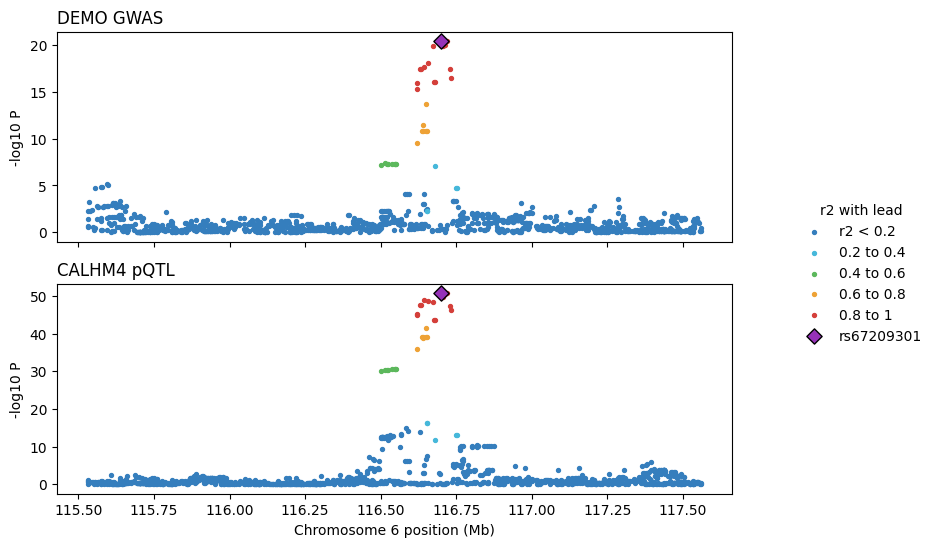

In [24]:
explorer.regional_plot("CALHM4");